(40000, 30) (10000, 30)
DecisionTree 최적 파라미터: {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 5}
DecisionTree 교차검증 F1: 0.3422
DecisionTree 테스트 F1: 0.3566
DecisionTree 테스트 Accuracy: 0.8315


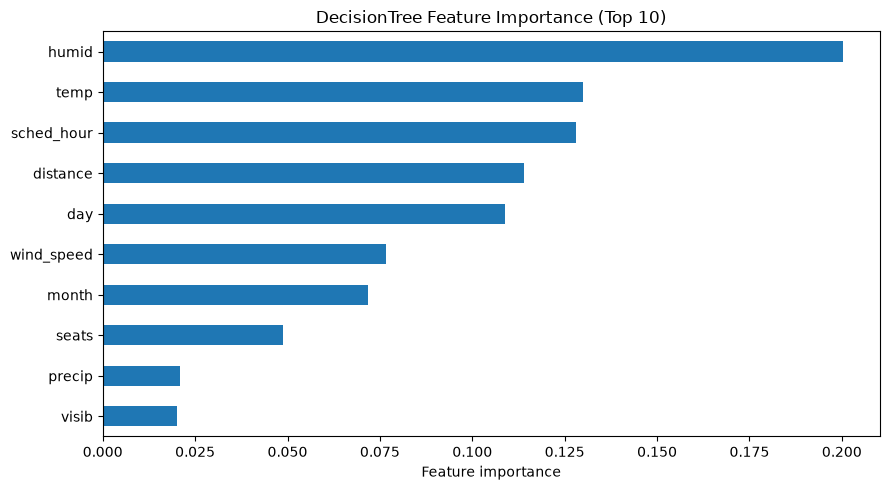

XGBoost 최적 파라미터: {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 300}
XGBoost 교차검증 F1: 0.3823
XGBoost 테스트 F1: 0.4036
XGBoost 테스트 Accuracy: 0.8590


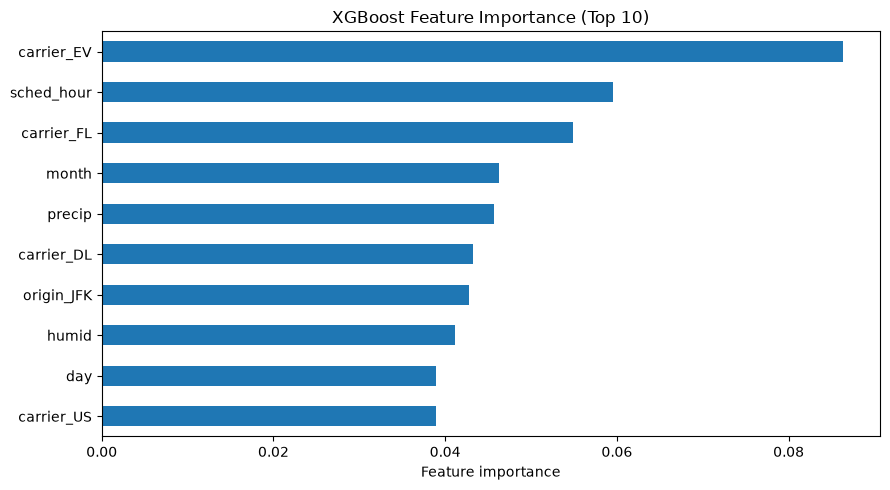

In [2]:
# 코드_공유.py
# 작업자 A, B, Admin 이 함께 사용하는 파일입니다.

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

# 2013년 뉴욕 출발 항공편 표본 50,000건입니다.
# 항공편 정보에 기상 정보와 기체 정보를 미리 결합해 두었습니다.
df = pd.read_csv('flights_ml.csv')

NUM = ['month', 'day', 'sched_hour', 'distance', 'temp', 'humid',
       'wind_speed', 'precip', 'visib', 'seats', 'engines']
CAT = ['carrier', 'origin']

X = pd.get_dummies(df[NUM + CAT], columns=CAT)
X = X.fillna(X.median(numeric_only=True))
y = df['is_delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)


####### A 작업자 작업 수행 #######

''' 코드 작성 바랍니다 '''
from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier

tree_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 10, 15],
    "min_samples_leaf": [1, 5, 20],
}

tree_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=tree_params,
    scoring="f1",
    cv=5,
)

tree_search.fit(X_train, y_train)
tree_model = tree_search.best_estimator_

tree_pred = tree_model.predict(X_test)
tree_f1 = f1_score(y_test, tree_pred)
tree_accuracy = accuracy_score(y_test, tree_pred)

print("DecisionTree 최적 파라미터:", tree_search.best_params_)
print(f"DecisionTree 교차검증 F1: {tree_search.best_score_:.4f}")
print(f"DecisionTree 테스트 F1: {tree_f1:.4f}")
print(f"DecisionTree 테스트 Accuracy: {tree_accuracy:.4f}")

tree_importance = pd.Series(
    tree_model.feature_importances_,
    index=X_train.columns,
)
tree_top10 = tree_importance.nlargest(10).sort_values()

ax = tree_top10.plot.barh(figsize=(9, 5))
ax.set_title("DecisionTree Feature Importance (Top 10)")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.show()

####### B 작업자 작업 수행 #######

''' 코드 작성 바랍니다 '''

from xgboost import XGBClassifier

xgb_params = {
    "max_depth": [3, 6, 9],
    "n_estimators": [100, 300],
    "learning_rate": [0.1, 0.05],
}

xgb_search = GridSearchCV(
    estimator=XGBClassifier(random_state=42),
    param_grid=xgb_params,
    scoring="f1",
    cv=5,
)

xgb_search.fit(X_train, y_train)
xgb_model = xgb_search.best_estimator_

xgb_pred = xgb_model.predict(X_test)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost 최적 파라미터:", xgb_search.best_params_)
print(f"XGBoost 교차검증 F1: {xgb_search.best_score_:.4f}")
print(f"XGBoost 테스트 F1: {xgb_f1:.4f}")
print(f"XGBoost 테스트 Accuracy: {xgb_accuracy:.4f}")

xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns,
)
xgb_top10 = xgb_importance.nlargest(10).sort_values()

ax = xgb_top10.plot.barh(figsize=(9, 5))
ax.set_title("XGBoost Feature Importance (Top 10)")
ax.set_xlabel("Feature importance")
plt.tight_layout()
plt.show()

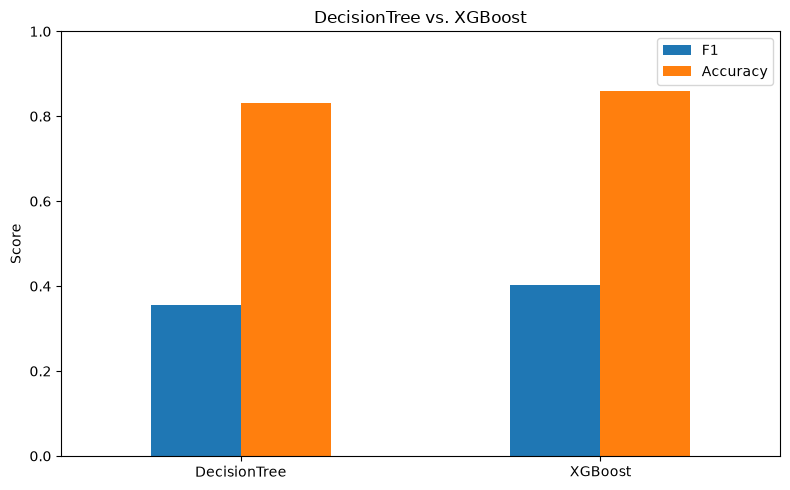

In [3]:
comparison = pd.DataFrame(
    {
        "F1": [tree_f1, xgb_f1],
        "Accuracy": [tree_accuracy, xgb_accuracy],
    },
    index=["DecisionTree", "XGBoost"],
)

ax = comparison.plot.bar(rot=0, ylim=(0, 1), figsize=(8, 5))
ax.set_title("DecisionTree vs. XGBoost")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

In [4]:
import subprocess

history = subprocess.run(
    ["git", "log", "--oneline", "-n", "20"],
    capture_output=True,
    text=True,
    check=True,
)
print(history.stdout)

8f0fa86 Merge pull request #2 from stonetiger95/B_branch
22a471f Merge branch 'main' into B_branch
c1f52ec Add XGBoost model and test alternate tree depths
cfaa4a3 Expand DecisionTree max_depth candidates
9315942 Merge pull request #1 from stonetiger95/A_branch
ca2684d Add DecisionTree model for flight delay prediction
ad8a268 Set up flight delay modeling workspace

